# Week 1 - Linear Regression 1
## Dataset: NOAA Storm Events

This week covers the basics of linear regression, with polynomial terms, interaction terms, multicollinearity and the variance inflation factor (VIF), and the difference between continuous and categorical features. For Storm Events, the question is how much of the property damage from a 2017 event can be explained by what kind of event it was, how strong it was, how long it lasted, when it happened, and who reported it.

In Module B, casualty counts explained very little of the damage (a random forest reached a test correlation of only 0.17), because deaths and injuries are consequences of an event, not measures of how strong it was. This notebook swaps them for features that describe the event itself, including the wind speed, hail size, and tornado path that NOAA records for some event types.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold, KFold,
                                     cross_val_score)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df), '| events with property damage above zero:', int((df['damageProperty'] > 0).sum()))

All 2017 events: 57041 | events with property damage above zero: 13439


### Target and features

The target is the base-10 log of property damage, for the 13,439 events in 2017 that reported damage above zero. Only about a quarter of all events report any damage, and whether damage happened at all is a different question, which Weeks 4 through 6 treat as a classification problem. Here the question is how large the damage was, given that there was some.

The categorical features are the event type (the ten most common, with the rest grouped as Other), the month, and the source of the report, such as an emergency manager, a trained spotter, the public, or an NWS storm survey. The continuous features are the log of event duration, wind speed in knots for wind events, hail diameter in inches for hail, and the log of tornado path length and width for tornadoes.

One detail matters a lot for the continuous features. NOAA stores wind speed and hail size in the same `MAGNITUDE` column, so a value of 2 could mean 2 knots or 2 inches depending on the event type. The notebook splits them into separate columns that are 0 for every other event type, and the same goes for tornado length and width.

The summary tables already show large differences. The median tornado reported $50,000 in damage and the median tropical storm event $100,000, while the median strong wind event reported $1,000. Events written up after an NWS storm survey have a median of $50,000, twenty times the $2,500 median for events reported through a 911 call center.

In [2]:
data = df[df['damageProperty'] > 0].copy()
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['month'] = begin.dt.month
data = data.dropna(subset=['month', 'durationHours']).reset_index(drop=True)

data['logDamage'] = np.log10(data['damageProperty'])
data['logDuration'] = np.log10(data['durationHours'] + 0.1)
top_types = data['EVENT_TYPE'].value_counts().head(10).index
data['eventType'] = data['EVENT_TYPE'].where(data['EVENT_TYPE'].isin(top_types), 'Other')
top_sources = data['SOURCE'].value_counts().head(10).index
data['source'] = data['SOURCE'].where(data['SOURCE'].isin(top_sources), 'Other')

# MAGNITUDE is a wind speed in knots for wind events and a hail diameter in inches for hail
# (the two damaged marine thunderstorm wind events fall in the 'Other' type and are left out here)
wind_types = ['Thunderstorm Wind', 'High Wind', 'Strong Wind']
data['isWind'] = data['EVENT_TYPE'].isin(wind_types).astype(float)
data['windKnots'] = np.where(data['isWind'] == 1, data['MAGNITUDE'], 0.0)
data['hailInches'] = np.where(data['EVENT_TYPE'] == 'Hail', data['MAGNITUDE'], 0.0)
data['isTornado'] = (data['EVENT_TYPE'] == 'Tornado').astype(float)
# Tornado path length (miles) and width (yards), logged and centered on the average tornado,
# and set to 0 for every other event type
log_len = np.log10(data['TOR_LENGTH'].fillna(0) + 0.1)
log_wid = np.log10(data['TOR_WIDTH'].fillna(0) + 1)
tor_rows = data['isTornado'] == 1
data['torLogLength'] = np.where(tor_rows, log_len - log_len[tor_rows].mean(), 0.0)
data['torLogWidth'] = np.where(tor_rows, log_wid - log_wid[tor_rows].mean(), 0.0)
print('Missing wind speeds among wind events:', int(data.loc[data['isWind'] == 1, 'MAGNITUDE'].isna().sum()),
      '| missing hail sizes among hail events:', int(data.loc[data['EVENT_TYPE'] == 'Hail', 'MAGNITUDE'].isna().sum()))
print('Damaged events used:', len(data), f"| median damage: ${data['damageProperty'].median():,.0f}")
print()
for col in ['eventType', 'source']:
    summary = data.groupby(col)['damageProperty'].agg(events='size', median_damage='median')
    summary['median_damage'] = summary['median_damage'].map('${:,.0f}'.format)
    print(summary.sort_values('events', ascending=False).to_string())
    print()

Missing wind speeds among wind events: 0 | missing hail sizes among hail events: 0
Damaged events used: 13439 | median damage: $8,000

                   events median_damage
eventType                              
Thunderstorm Wind    7146        $5,000
Flash Flood          1288       $10,000
Strong Wind          1044        $1,000
Tornado               910       $50,000
Flood                 655       $10,000
Other                 649       $30,000
Hail                  635       $10,000
High Wind             440       $25,000
Lightning             300       $10,000
Tropical Storm        234      $100,000
Winter Storm          138       $20,000

                   events median_damage
source                                 
Emergency Manager    2653       $10,000
Other                2587       $10,000
Law Enforcement      1541        $8,000
Public               1316        $5,000
911 Call Center      1114        $2,500
NWS Storm Survey     1098       $50,000
Trained Spotter       97

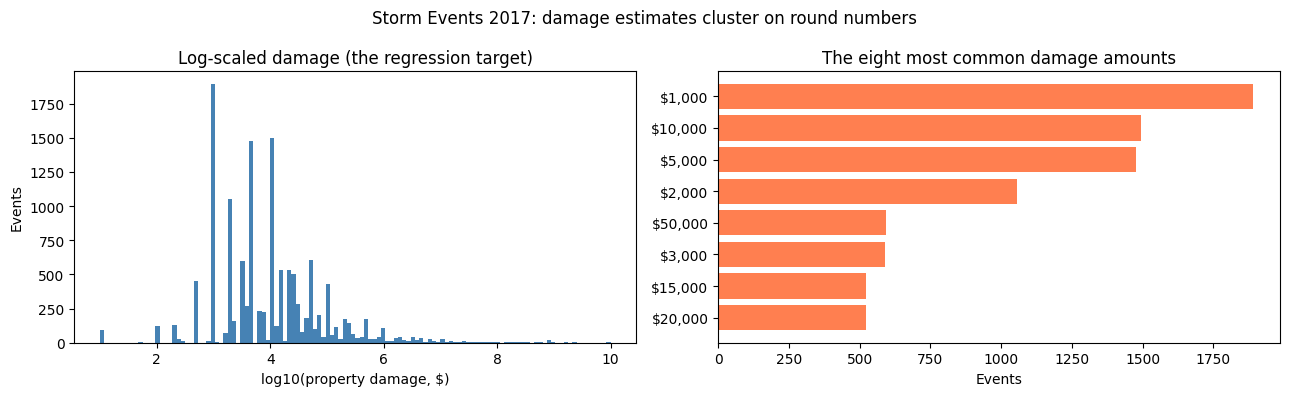

Share of damage values with a single significant digit (like $5,000 or $20,000): 0.812


In [3]:
first_digit_only = data['damageProperty'] / 10 ** np.floor(np.log10(data['damageProperty']))
round_share = np.isclose(first_digit_only, np.round(first_digit_only)).mean()
common = data['damageProperty'].value_counts().head(8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(data['logDamage'], bins=120, color='steelblue')
axes[0].set_xlabel('log10(property damage, $)')
axes[0].set_ylabel('Events')
axes[0].set_title('Log-scaled damage (the regression target)')
axes[1].barh([f'${v:,.0f}' for v in common.index], common.values, color='coral')
axes[1].invert_yaxis()
axes[1].set_xlabel('Events')
axes[1].set_title('The eight most common damage amounts')
fig.suptitle('Storm Events 2017: damage estimates cluster on round numbers')
plt.tight_layout()
plt.show()
print(f'Share of damage values with a single significant digit (like $5,000 or $20,000): {round_share:.3f}')

In [4]:
y = data['logDamage'].values
groups = data['EPISODE_ID'].values
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(data, y, groups))
gkf = GroupKFold(n_splits=5)
print('Training events:', len(train_idx), '| test events:', len(test_idx),
      '| episodes in both:', len(set(groups[train_idx]) & set(groups[test_idx])))


def evaluate(name, X, model=None):
    """Training, grouped 5-fold cross-validated, and test R-squared for one feature set."""
    model = model if model is not None else LinearRegression()
    cv_r2 = cross_val_score(model, X.iloc[train_idx], y[train_idx], cv=gkf, groups=groups[train_idx],
                            scoring='r2').mean()
    model.fit(X.iloc[train_idx], y[train_idx])
    pred_train, pred_test = model.predict(X.iloc[train_idx]), model.predict(X.iloc[test_idx])
    return {'Model': name, 'Columns': X.shape[1],
            'Train R2': r2_score(y[train_idx], pred_train), 'CV R2': cv_r2,
            'Test R2': r2_score(y[test_idx], pred_test),
            'Test RMSE (log10)': mean_squared_error(y[test_idx], pred_test) ** 0.5}


def dummies(cols):
    return pd.get_dummies(data[cols], drop_first=True, dtype=float)

Training events: 10140 | test events: 3299 | episodes in both: 0


The histogram is the most important EDA result in this notebook. About 81% of damage values have a single significant digit, like $1,000, $5,000, or $20,000, and the eight most common values alone account for more than half of all damaged events. Damage in this dataset is an estimate written down by a person, not a measurement, and that puts a ceiling on how much any model can explain.

The split keeps whole storm episodes together, so no storm appears in both the training and the test set, and cross-validation uses `GroupKFold` by episode for the same reason. Events in one episode share the same weather and are often written up by the same office, so a random split would let the model score well by recognizing storms it had already seen.

### Categorical features

Each categorical feature becomes a set of 0/1 dummy columns, with one category left out as the baseline that the others are compared with. The next cell builds the model up one feature at a time. It also tries the month two ways, once as a single number from 1 to 12 and once as 11 dummy columns.

                                          Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
                              Log duration only        1    0.1139 0.1110   0.1546             0.9409
                                Event type only       10    0.2084 0.1948   0.1723             0.9310
  Event type + log duration + month as a number       12    0.2772 0.2653   0.2825             0.8668
Event type + log duration + month as categories       22    0.2915 0.2657   0.3003             0.8560
                                + report source       32    0.3324 0.3043   0.3429             0.8295

Baseline report source: 911 Call Center
Damage multiplier by report source, relative to the baseline:
Amateur Radio         1.27
State Official        1.75
Other                 1.82
Public                1.84
Social Media          2.09
Trained Spotter       2.20
Law Enforcement       2.38
Broadcast Media       3.33
Emergency Manager     3.54
NWS Storm Survey     13.94


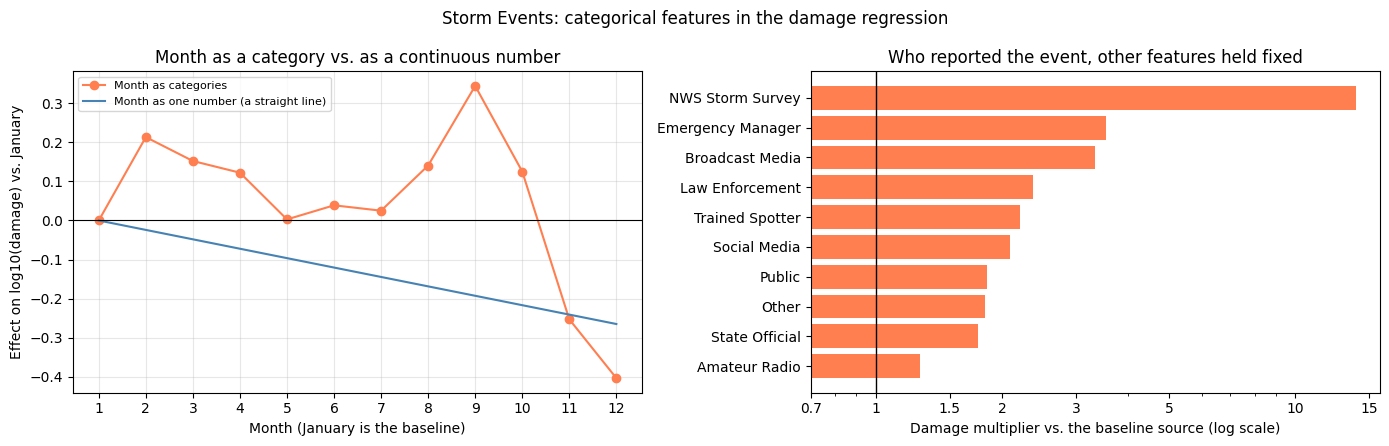

In [5]:
month_dummies = pd.get_dummies(data['month'].astype(int), prefix='month', drop_first=True, dtype=float)
rows = []
rows.append(evaluate('Log duration only', data[['logDuration']]))
rows.append(evaluate('Event type only', dummies(['eventType'])))
X_month_num = data[['logDuration', 'month']].join(dummies(['eventType']))
rows.append(evaluate('Event type + log duration + month as a number', X_month_num))
X_month_cat = data[['logDuration']].join(dummies(['eventType'])).join(month_dummies)
rows.append(evaluate('Event type + log duration + month as categories', X_month_cat))
X_source = X_month_cat.join(dummies(['source']))
rows.append(evaluate('+ report source', X_source))
print(pd.DataFrame(rows).round(4).to_string(index=False))

m_num = LinearRegression().fit(X_month_num.iloc[train_idx], y[train_idx])
m_src = LinearRegression().fit(X_source.iloc[train_idx], y[train_idx])
coef = pd.Series(m_src.coef_, index=X_source.columns)
month_effect = pd.Series([0.0] + [coef[f'month_{m}'] for m in range(2, 13)], index=range(1, 13))
src_mult = (10 ** coef[[c for c in X_source.columns if c.startswith('source_')]]).sort_values()
print()
print('Baseline report source:', sorted(data['source'].unique())[0])
print('Damage multiplier by report source, relative to the baseline:')
print(src_mult.round(2).rename(lambda n: n.replace('source_', '')).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 13), month_effect.values, marker='o', color='coral', label='Month as categories')
linear = m_num.coef_[list(X_month_num.columns).index('month')] * (np.arange(1, 13) - 1)
axes[0].plot(range(1, 13), linear, color='steelblue', label='Month as one number (a straight line)')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel('Month (January is the baseline)')
axes[0].set_ylabel('Effect on log10(damage) vs. January')
axes[0].set_title('Month as a category vs. as a continuous number')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].barh([n.replace('source_', '') for n in src_mult.index], src_mult.values,
             color=np.where(src_mult.values > 1, 'coral', 'steelblue'))
axes[1].axvline(1, color='black', linewidth=1)
axes[1].set_xscale('log')
ticks = [0.7, 1, 1.5, 2, 3, 5, 10, 15]
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([str(t) for t in ticks])
axes[1].xaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_xlabel('Damage multiplier vs. the baseline source (log scale)')
axes[1].set_title('Who reported the event, other features held fixed')
fig.suptitle('Storm Events: categorical features in the damage regression')
plt.tight_layout()
plt.show()

Event type alone explains about 19% of the variance in cross-validation, and adding log duration and month raises that to about 27%. The report source adds another 0.04 (CV R-squared 0.304, test 0.343).

The month comparison is a good example of why a categorical feature should not be entered as a number. As one number, month forces a straight line from January to December, and the fitted line slopes gently downward. As categories, the model finds the real pattern, which is not a line at all. Damage per event peaks in September (about 0.34 log10 units, or roughly 2.2 times, above January), when Harvey and Irma hit, and drops sharply in November and December. The two versions score about the same in cross-validation (0.2653 and 0.2657), but the categorical version does better on the test episodes (0.300 against 0.283), and it is the only one that describes the season correctly.

The report source has the largest effects in this notebook. Holding event type, duration, and month fixed, an event documented by an NWS storm survey reports about 14 times the damage of one reported through a 911 call center, and emergency managers and broadcast media report about 3.5 and 3.3 times as much. This is almost certainly selection, not cause. The NWS sends survey teams to the worst damage, so the source of the report is partly a result of how bad the damage was. That makes it a useful predictor but a dangerous one to read as an effect.

### Magnitude, and why it needs an interaction with event type

The `MAGNITUDE` column holds wind speed for wind events and hail size for hail. Putting it in as one column gives every event type the same slope, so one more "unit" means the same thing whether it is a knot or an inch. Splitting it into a wind speed column and a hail size column, each 0 for other event types, is the same as interacting magnitude with the event type. Each type then gets its own slope in its own units.

In [6]:
X_raw_mag = X_source.join(data['MAGNITUDE'].fillna(0).rename('magnitudeRaw'))
rows.append(evaluate('+ MAGNITUDE as one column (knots and inches mixed)', X_raw_mag))
X_mag = X_source.join(data[['windKnots', 'hailInches']])
rows.append(evaluate('+ wind speed and hail size as separate columns', X_mag))
print(pd.DataFrame(rows[-3:]).round(4).to_string(index=False))

m_raw = LinearRegression().fit(X_raw_mag.iloc[train_idx], y[train_idx])
m_mag = LinearRegression().fit(X_mag.iloc[train_idx], y[train_idx])
c_raw = pd.Series(m_raw.coef_, index=X_raw_mag.columns)
c_mag = pd.Series(m_mag.coef_, index=X_mag.columns)
print()
print(f"One shared slope: {(10 ** c_raw['magnitudeRaw'] - 1) * 100:+.1f}% damage per unit, whether the unit is a knot or an inch")
print(f"Separate slopes: {(10 ** (10 * c_mag['windKnots']) - 1) * 100:+.1f}% per 10 knots of wind, "
      f"{(10 ** c_mag['hailInches'] - 1) * 100:+.1f}% per inch of hail")

                                             Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
                                   + report source       32    0.3324 0.3043   0.3429             0.8295
+ MAGNITUDE as one column (knots and inches mixed)       33    0.3722 0.3431   0.3907             0.7988
    + wind speed and hail size as separate columns       34    0.4025 0.3742   0.4113             0.7851

One shared slope: +8.8% damage per unit, whether the unit is a knot or an inch
Separate slopes: +140.9% per 10 knots of wind, +927.9% per inch of hail


Even the single mixed column helps (CV R-squared 0.304 to 0.343), because within each event type larger values do mean more damage. But its slope is a compromise. It says damage rises about 8.8% per unit, which is far too much for one knot and far too little for one inch. With separate columns, damage rises about 141% per 10 knots of wind and about 928% per inch of hail, and CV R-squared goes up again to 0.374.

### A polynomial in wind speed

Thunderstorm wind is the most common damaging event, so the shape of its wind speed effect matters. The physical force of wind grows faster than its speed, so damage could plausibly curve upward. The next cell fits polynomials of degree 1 to 6 in wind speed using only the thunderstorm wind events in the training set, with grouped cross-validation, and plots them against the average damage in 5-knot bins.

Thunderstorm wind events in the training set: 5,460
Share reported at exactly 50 knots: 0.412 | share with an estimated (EG) rather than measured gust: 0.976
 Degree  Train R2  Grouped CV R2
      1    0.2849         0.2684
      2    0.2906         0.2742
      3    0.2966         0.2794
      4    0.2995         0.2790
      5    0.3012         0.2816
      6    0.3020         0.2799


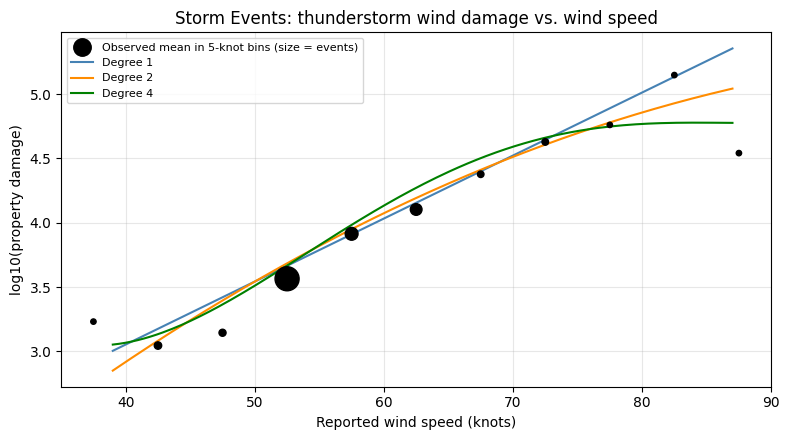

In [7]:
tw = data.iloc[train_idx]
tw = tw[tw['EVENT_TYPE'] == 'Thunderstorm Wind']
center = 50
deg_rows = []
for degree in range(1, 7):
    Xw = pd.DataFrame({f'wind^{k}': ((tw['MAGNITUDE'] - center) / 10) ** k for k in range(1, degree + 1)})
    cv_r2 = cross_val_score(LinearRegression(), Xw, tw['logDamage'], cv=gkf, groups=tw['EPISODE_ID'], scoring='r2').mean()
    fit_r2 = LinearRegression().fit(Xw, tw['logDamage']).score(Xw, tw['logDamage'])
    deg_rows.append({'Degree': degree, 'Train R2': fit_r2, 'Grouped CV R2': cv_r2})
print(f'Thunderstorm wind events in the training set: {len(tw):,}')
print(f"Share reported at exactly 50 knots: {(tw['MAGNITUDE'] == 50).mean():.3f} | "
      f"share with an estimated (EG) rather than measured gust: {(tw['MAGNITUDE_TYPE'] == 'EG').mean():.3f}")
print(pd.DataFrame(deg_rows).round(4).to_string(index=False))

bins = tw.groupby((tw['MAGNITUDE'] // 5) * 5 + 2.5)['logDamage'].agg(['mean', 'size'])
bins = bins[bins['size'] >= 20]
grid = np.linspace(tw['MAGNITUDE'].quantile(0.005), tw['MAGNITUDE'].quantile(0.995), 200)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(bins.index, bins['mean'], s=np.clip(bins['size'] / 8, 15, 300), color='black', zorder=3,
           label='Observed mean in 5-knot bins (size = events)')
for degree, color in [(1, 'steelblue'), (2, 'darkorange'), (4, 'green')]:
    Xw = pd.DataFrame({f'wind^{k}': ((tw['MAGNITUDE'] - center) / 10) ** k for k in range(1, degree + 1)})
    m = LinearRegression().fit(Xw, tw['logDamage'])
    Xg = pd.DataFrame({f'wind^{k}': ((grid - center) / 10) ** k for k in range(1, degree + 1)})
    ax.plot(grid, m.predict(Xg), color=color, label=f'Degree {degree}')
ax.set_xlabel('Reported wind speed (knots)')
ax.set_ylabel('log10(property damage)')
ax.set_title('Storm Events: thunderstorm wind damage vs. wind speed')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
wind_c = (data['windKnots'] - 50) / 10 * data['isWind']
X_wpoly = X_source.join(data[['hailInches']])
for k in range(1, 4):
    X_wpoly[f'wind^{k}'] = wind_c ** k
rows.append(evaluate('+ hail size + centered cubic in wind speed', X_wpoly))
X_tor = X_wpoly.join(data[['torLogLength', 'torLogWidth']])
rows.append(evaluate('+ tornado log length and log width', X_tor))
X_tor_int = X_tor.copy()
X_tor_int['torLogLength x torLogWidth'] = data['torLogLength'] * data['torLogWidth']
rows.append(evaluate('+ tornado length x width interaction', X_tor_int))
print(pd.DataFrame(rows[-3:]).round(4).to_string(index=False))

m_tor = LinearRegression().fit(X_tor_int.iloc[train_idx], y[train_idx])
ct = pd.Series(m_tor.coef_, index=X_tor_int.columns)
print()
print('Tornado terms:', ct[['torLogLength', 'torLogWidth', 'torLogLength x torLogWidth']].round(3).to_dict())
tor = data[data['isTornado'] == 1]
print(f"Tornadoes: {len(tor)} | correlation of log damage with log length {tor['logDamage'].corr(tor['torLogLength']):.2f}, "
      f"with log width {tor['logDamage'].corr(tor['torLogWidth']):.2f}, "
      f"with their product {tor['logDamage'].corr(tor['torLogLength'] * tor['torLogWidth']):.2f}")

                                     Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
+ hail size + centered cubic in wind speed       36    0.4058 0.3772   0.4108             0.7855
        + tornado log length and log width       38    0.4101 0.3808   0.4139             0.7834
      + tornado length x width interaction       39    0.4108 0.3818   0.4141             0.7833

Tornado terms: {'torLogLength': 0.192, 'torLogWidth': 0.393, 'torLogLength x torLogWidth': 0.393}
Tornadoes: 910 | correlation of log damage with log length 0.37, with log width 0.45, with their product 0.15


The curve is weaker than I expected. Damage rises steadily with wind speed. The average log damage corresponds to roughly $1,100 to $1,700 in the bins below 50 knots and about $43,000 at 70 to 75 knots, but a straight line on the log scale already captures most of that rise. Cross-validated R-squared goes from 0.268 with a line to 0.279 with a cubic, and the higher degrees add almost nothing. Degree 4 also flattens out at the top, where there are very few events, which is the usual way a high-degree polynomial misbehaves at the edge of the data.

The wind speeds themselves explain part of this. About 98% of thunderstorm wind speeds are estimated gusts rather than measured ones, and 41% of them are exactly 50 knots, which is the threshold for a severe thunderstorm. For many events, 50 knots probably means "severe enough to cause damage" more than a real reading, which blurs any curve.

The second cell adds a centered cubic in wind speed and the tornado features to the full model. Tornado path length and width both raise damage, and their product adds a little on top (coefficient 0.39), meaning a tornado that is both long and wide does more damage than the two effects added separately would suggest. That fits the fact that the damaged area is roughly length times width. Each of these steps adds only 0.001 to 0.004 in CV R-squared, so the model is close to what these features can explain.

### Multicollinearity and the variance inflation factor

The VIF measures how much a coefficient's variance is inflated because its feature can be predicted from the others. The next cell compares raw wind speed powers with centered ones, checks the VIFs of the full model, and shows the dummy variable trap for event type.

In [9]:
def vif(X):
    Z = (X - X.mean()) / X.std()
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z.values, rowvar=False))), index=X.columns)


X_raw_powers = X_source.join(data[['hailInches']])
for k in range(1, 4):
    X_raw_powers[f'wind^{k}'] = (data['windKnots'] / 10) ** k
v = pd.DataFrame({'Raw wind powers': vif(X_raw_powers), 'Centered wind powers': vif(X_wpoly)})
print('VIF for the wind terms and the event-type indicators they overlap with:')
show = ['wind^1', 'wind^2', 'wind^3', 'eventType_Thunderstorm Wind', 'eventType_Strong Wind', 'eventType_High Wind']
print(v.loc[show].round(1).to_string())

full_vif = vif(X_tor_int).sort_values(ascending=False)
print()
print('Largest VIFs in the full hand-built model:')
print(full_vif.head(8).round(2).to_string())
print('Features with VIF above 10:', int((full_vif > 10).sum()), 'of', len(full_vif))

m_a = LinearRegression().fit(X_raw_powers.iloc[train_idx], y[train_idx])
m_b = LinearRegression().fit(X_wpoly.iloc[train_idx], y[train_idx])
print()
print(f'Largest difference in test predictions, raw vs. centered powers: '
      f'{np.abs(m_a.predict(X_raw_powers.iloc[test_idx]) - m_b.predict(X_wpoly.iloc[test_idx])).max():.2e}')

all_types = pd.get_dummies(data['eventType'], dtype=float)
trap = np.column_stack([np.ones(len(data)), all_types.values])
print(f'Intercept plus all {all_types.shape[1]} event-type dummies: {trap.shape[1]} columns, rank {np.linalg.matrix_rank(trap)}')

VIF for the wind terms and the event-type indicators they overlap with:
                             Raw wind powers  Centered wind powers
wind^1                               16518.0                   3.0
wind^2                               16823.5                   5.3
wind^3                                2203.0                   5.1
eventType_Thunderstorm Wind           2294.4                   5.8
eventType_Strong Wind                  628.8                   3.1
eventType_High Wind                    291.9                   1.5

Largest VIFs in the full hand-built model:
eventType_Hail                 7.27
hailInches                     6.30
eventType_Thunderstorm Wind    5.86
wind^2                         5.30
wind^3                         5.09
eventType_Tornado              4.65
logDuration                    4.57
source_NWS Storm Survey        4.35
Features with VIF above 10: 0 of 39

Largest difference in test predictions, raw vs. centered powers: 1.71e-13
Intercept plus a

Raw wind powers are badly collinear. Their VIFs are about 16,500, 16,800, and 2,200, and the thunderstorm wind indicator reaches about 2,300. The reason is that wind speed is 0 for non-wind events and between about 30 and 100 knots for wind events, so the raw speed, its square, its cube, and the thunderstorm wind indicator all mostly measure the same thing, which is whether this is a wind event. Centering the speed at 50 knots before raising it to a power brings the VIFs down to between 3 and 6. The tornado features had the same problem in an earlier version of this notebook, since they are 0 for every non-tornado, and centering them on the average tornado fixed it. In the final model no feature has a VIF above 10, and the largest is 7.3 for the hail indicator, which overlaps with hail size.

As in the NFIP notebook, the raw and centered versions make identical predictions (to within about $10^{-13}$). This kind of multicollinearity comes from how the terms are written. It makes individual coefficients unstable and hard to read but does not change what the model predicts.

The dummy trap appears again. An intercept plus all 11 event-type dummies gives 12 columns but a rank of 11, because the dummies always add up to 1. Dropping one type as the baseline removes the problem.

### Every interaction at once, and overfitting

The last experiment adds every pairwise product of the 38 columns, 741 columns in total, and checks it three ways. It compares training, cross-validated, and test R-squared, scores the same models with a random split that ignores storm episodes, and refits both models on training sets from 500 events up to the full 10,140.

                               Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
Every pairwise interaction, degree 1       38    0.4101 0.3808   0.4139             0.7834
Every pairwise interaction, degree 2      741    0.5490 0.3507   0.3507             0.8245



                     Model  Random-split CV R2  Random-split test R2  Episode-split test R2
          Hand-built model              0.4040                0.4229                 0.4139
Every pairwise interaction              0.4466                0.4667                 0.3507



Model            Every pairwise interaction  Hand-built
Training events                                        
500                             -516497.299       0.376
1000                                -11.460       0.380
2000                                  0.010       0.405
4000                                  0.061       0.409
8000                                  0.250       0.414
10140                                 0.351       0.414


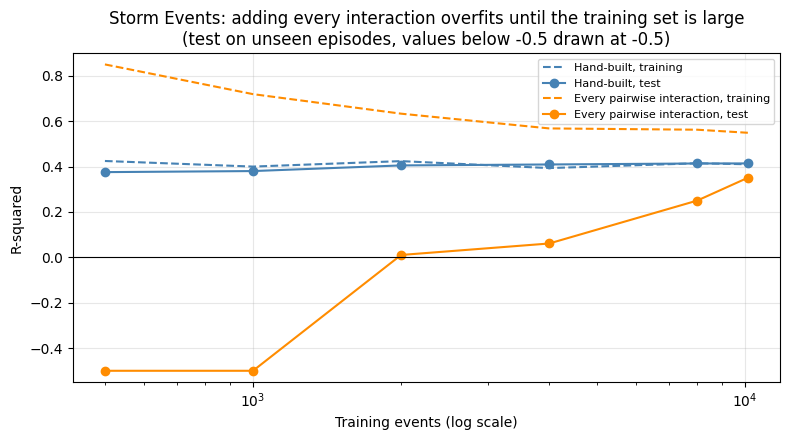

In [10]:
def expanded(X, degree):
    # Products of every pair of columns (the wind powers are already in X, so no extra squares)
    poly = PolynomialFeatures(degree, interaction_only=True, include_bias=False)
    return make_pipeline(StandardScaler(), poly, LinearRegression())


expansion = []
for degree in [1, 2]:
    row = evaluate(f'Every pairwise interaction, degree {degree}', X_tor, expanded(X_tor, degree))
    row['Columns'] = PolynomialFeatures(degree, interaction_only=True, include_bias=False).fit(X_tor.iloc[:5]).n_output_features_
    expansion.append(row)
print(pd.DataFrame(expansion).round(4).to_string(index=False))

# The same two models scored with an ordinary random split, ignoring storm episodes
r_train, r_test = train_test_split(np.arange(len(data)), test_size=0.25, random_state=0)
compare = []
for name, model in [('Hand-built model', LinearRegression()), ('Every pairwise interaction', expanded(X_tor, 2))]:
    model.fit(X_tor.iloc[r_train], y[r_train])
    random_test = r2_score(y[r_test], model.predict(X_tor.iloc[r_test]))
    random_cv = cross_val_score(model, X_tor.iloc[r_train], y[r_train], cv=KFold(5, shuffle=True, random_state=0),
                                scoring='r2').mean()
    model.fit(X_tor.iloc[train_idx], y[train_idx])
    compare.append({'Model': name, 'Random-split CV R2': random_cv, 'Random-split test R2': random_test,
                    'Episode-split test R2': r2_score(y[test_idx], model.predict(X_tor.iloc[test_idx]))})
print()
print(pd.DataFrame(compare).round(4).to_string(index=False))

sizes = [500, 1000, 2000, 4000, 8000, len(train_idx)]
rng = np.random.RandomState(0)
curve = []
for n in sizes:
    sub = rng.choice(train_idx, n, replace=False) if n < len(train_idx) else train_idx
    for name, model in [('Hand-built', LinearRegression()), ('Every pairwise interaction', expanded(X_tor, 2))]:
        model.fit(X_tor.iloc[sub], y[sub])
        curve.append({'Training events': n, 'Model': name,
                      'Train R2': r2_score(y[sub], model.predict(X_tor.iloc[sub])),
                      'Test R2': r2_score(y[test_idx], model.predict(X_tor.iloc[test_idx]))})
curve = pd.DataFrame(curve)
print()
print(curve.pivot(index='Training events', columns='Model', values='Test R2').round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in [('Hand-built', 'steelblue'), ('Every pairwise interaction', 'darkorange')]:
    part = curve[curve['Model'] == name]
    ax.semilogx(part['Training events'], part['Train R2'], '--', color=color, label=f'{name}, training')
    ax.semilogx(part['Training events'], part['Test R2'].clip(lower=-0.5), '-o', color=color, label=f'{name}, test')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylim(-0.55, 0.9)
ax.set_xlabel('Training events (log scale)')
ax.set_ylabel('R-squared')
ax.set_title('Storm Events: adding every interaction overfits until the training set is large\n(test on unseen episodes, values below -0.5 drawn at -0.5)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final evaluation on held-out storm episodes

                               Model  Columns  CV R2
  + tornado log length and log width       38 0.3808
+ tornado length x width interaction       39 0.3818
Every pairwise interaction, degree 2      741 0.3507
Chosen by grouped cross-validation: + tornado length x width interaction

Test R2: 0.4141 | test RMSE: 0.783 log10 units (a typical miss of about 6.1x)
Share of test events predicted within a factor of 3 of the reported damage: 0.527
Same share when every event is predicted at the training average: 0.385

Mean error (predicted minus actual, log10) by event type on the test set:
                    mean  size
type                          
Flood             -0.168   172
Flash Flood       -0.122   315
Hail              -0.107   157
Strong Wind       -0.003   272
Tornado            0.019   219
Thunderstorm Wind  0.020  1686
Lightning          0.093    67
Tropical Storm     0.191   110
High Wind          0.206   117
Other              0.301   155
Winter Storm       0.367    29


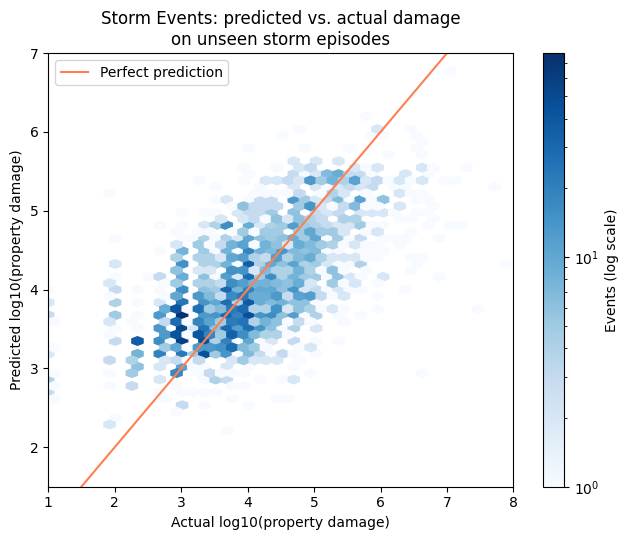

In [11]:
candidates = pd.DataFrame([rows[-2], rows[-1], expansion[1]])
print(candidates[['Model', 'Columns', 'CV R2']].round(4).to_string(index=False))
best = candidates.loc[candidates['CV R2'].idxmax(), 'Model']
print('Chosen by grouped cross-validation:', best)
if best.startswith('Every'):
    final_X, final_model = X_tor, expanded(X_tor, 2)
elif 'interaction' in best:
    final_X, final_model = X_tor_int, LinearRegression()
else:
    final_X, final_model = X_tor, LinearRegression()
final_model.fit(final_X.iloc[train_idx], y[train_idx])
pred = final_model.predict(final_X.iloc[test_idx])
rmse = mean_squared_error(y[test_idx], pred) ** 0.5
naive = np.full(len(test_idx), y[train_idx].mean())
print()
print(f'Test R2: {r2_score(y[test_idx], pred):.4f} | test RMSE: {rmse:.3f} log10 units (a typical miss of about {10 ** rmse:.1f}x)')
print(f'Share of test events predicted within a factor of 3 of the reported damage: {(10 ** np.abs(pred - y[test_idx]) <= 3).mean():.3f}')
print(f'Same share when every event is predicted at the training average: {(10 ** np.abs(naive - y[test_idx]) <= 3).mean():.3f}')

resid = pd.DataFrame({'type': data['eventType'].values[test_idx], 'error': pred - y[test_idx]})
print()
print('Mean error (predicted minus actual, log10) by event type on the test set:')
print(resid.groupby('type')['error'].agg(['mean', 'size']).round(3).sort_values('mean').to_string())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
hb = ax.hexbin(y[test_idx], pred, gridsize=50, bins='log', cmap='Blues', mincnt=1)
ax.plot([1, 8], [1, 8], color='coral', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(1, 8)
ax.set_ylim(1.5, 7)
ax.set_xlabel('Actual log10(property damage)')
ax.set_ylabel('Predicted log10(property damage)')
ax.set_title('Storm Events: predicted vs. actual damage\non unseen storm episodes')
fig.colorbar(hb, ax=ax, label='Events (log scale)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

The full interaction model is a clear case of overfitting. Its training R-squared is 0.549, far above the hand-built model's 0.410, but on unseen episodes it drops to 0.351, worse than the hand-built model's 0.414. The learning curve shows it needs most of the training set to get above zero at all (-11.5 with 1,000 events and 0.01 with 2,000), while the hand-built model already reaches 0.38 with 500 events.

The random split hides this. Under a random split the interaction model looks better than the hand-built one (test R-squared 0.467 against 0.423), and only the episode split shows it is worse. With 741 columns, the model can memorize combinations that belong to a particular storm, and a random split rewards that because other events from the same storm are in the test set.

Grouped cross-validation picked the hand-built model with the tornado interaction. On the held-out episodes it reaches a test R-squared of 0.414 and an RMSE of 0.783 in log10 units, so a typical prediction is off by a factor of about 6. It gets 52.7% of test events within a factor of 3 of the reported damage, against 38.5% when every event is predicted at the training average. By event type, it underpredicts floods and flash floods and overpredicts winter storms, high wind, and the Other group.

## Discussion

### Overfitting

Two things were done to keep the models honest. Every comparison used grouped 5-fold cross-validation on the training set, and the final model was checked once on 3,299 test events from storm episodes the model never saw. Grouping by episode turned out to matter as much as the model choice. The full interaction model looked like the best model under a random split and the worst under the episode split, so without grouping I would have picked the most overfit model.

The size of the feature set was the other lever. The hand-built model with 39 columns has a train minus CV gap of about 0.03, small and steady at every training size. Expanding to 741 columns raised the gap to about 0.20 (training 0.549 against CV 0.351), and the learning curve showed that the test score collapses with smaller samples, down to about -516,000 with 500 events, where there are more columns than rows. Centering the polynomial terms did not prevent overfitting, since it does not change the predictions, but it kept the coefficients readable.

### Metrics and hyperparameter tuning

R-squared on log damage was the main metric, with RMSE in log10 units reported next to it. Converting the RMSE with $10^{\text{RMSE}}$ gives a typical multiplicative error, which is easier to explain than a log error. The share of events predicted within a factor of 3 is the most practical number, since damage values are rounded estimates and getting the order of magnitude right is what matters.

The settings chosen here were the degree of the wind polynomial (degree 3, where grouped CV stopped improving), whether to treat month as a number or as categories (categories), and whether to add every interaction (no). Each choice trades flexibility against stability, and grouped cross-validation made the call in each case.

### Expected or unexpected

I expected event type and wind speed to matter, and they do. I did not expect the report source to matter as much as it does. A storm survey report carries about 14 times the damage of a 911 report after controlling for everything else. That is a useful warning for the Capstone, because the source is decided after the damage happens, so it behaves more like a description of the damage than a driver of it.

The weak curvature in the wind speed effect was also unexpected, since wind force grows faster than wind speed. The rounding of wind speeds (41% at exactly 50 knots, almost all estimated) probably hides most of the curve that a measured wind speed would show.

The biggest surprise was how much the random split flattered the full interaction model. I expected some difference, but the two splits ranked the models in opposite orders.

### How EDA helped

EDA helped in three specific places. The Module B finding that damage is extremely right-skewed is why the target is logged. Looking at the most common damage values showed that about 81% are single-digit round numbers, which sets realistic expectations for R-squared. And reading the NOAA field descriptions showed that `MAGNITUDE` mixes knots and inches, which is the reason for the type-specific magnitude columns, one of the biggest improvements in the notebook (CV R-squared 0.304 to 0.374).

The month plot is a case where EDA and modeling worked together. Fitting month as categories revealed the September peak, which matches the Harvey and Irma timing seen in Module B.

### External sources

- scikit-learn User Guide, "Polynomial features," in the Preprocessing data chapter: https://scikit-learn.org/stable/modules/preprocessing.html#polynomial-features
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 3 ("Linear Regression"), on qualitative predictors, interaction terms, and collinearity.
- Penn State STAT 501, Lesson 12, on detecting multicollinearity with VIFs and reducing structural multicollinearity by centering: https://online.stat.psu.edu/stat501/lesson/12
- NOAA National Centers for Environmental Information, Storm Events Database documentation, for the meaning of `MAGNITUDE`, `MAGNITUDE_TYPE`, and the tornado path fields: https://www.ncdc.noaa.gov/stormevents/


### Conclusions

Using event type, month, duration, report source, and type-specific intensity measures, a linear regression explains about 41% of the variation in log property damage on storm episodes it never saw (test R-squared 0.414). That is a large step up from the casualty-based models in Module B. Treating categorical features correctly made the biggest difference, both for the month, where a single number hid the September peak, and for `MAGNITUDE`, where separate columns for knots and inches added about 0.03 in CV R-squared.

For the Capstone, two cautions carry forward. Storm Events damage values are rounded human estimates, so a typical prediction will be off by several times no matter how good the model is. And some of the strongest predictors, such as the report source, describe how an event was recorded rather than what the storm did, so they should be kept out of any model meant to explain damage from storm conditions.